# Short-Term Load Forecasting (STLF) — Model Training & Evaluation

This notebook trains and benchmarks five models for **day-ahead hourly power demand forecasting in Ecuador** (`demand_mw`) using the processed dataset produced by `01_data_ingestion_and_preprocessing.ipynb`.

**Forecasting task (day-ahead).** Every day at 23:00, the 24 hourly demands of the next day are forecast using only the demand observed up to that moment (the last 72 hours), together with the calendar, cyclical and weather values of the target hours. The lead time is therefore 1 h for 00:00 and 24 h for 23:00 of the target day, as in the operational day-ahead process and in the CENACE reference study (Brito & Sánchez, 2026). Weather is taken from the observed record, i.e. a perfect day-ahead weather forecast is assumed.

| Role | Model | Day-ahead strategy |
|---|---|---|
| Baseline 0 (statistical) | SARIMAX | 24-step forecast from the 23:00 origin |
| Baseline 1 (paper replication) | XGBoost Regressor | one model per lead time (24 models) |
| Baseline 2 (paper replication) | LSTM Network | one network with 24 outputs |
| Proposed 1 | LightGBM Regressor | one model per lead time (24 models) |
| Proposed 2 | GRU Network | one network with 24 outputs |

**Structure**
1. Environment setup & data pipeline
2. Model training & comparative benchmark
3. Evaluation metrics & output export

All randomness is fixed with seed `42` for strict reproducibility.

---
## Section 1: Environment Setup & Data Pipeline

### 1.1 Install dependencies
XGBoost, LightGBM and TensorFlow are pre-installed on Colab. The command below is a no-op for packages that are already available.

In [1]:
%pip install -q xgboost lightgbm tabulate

### 1.2 Mount Google Drive and define project paths
The dataset is read from `Project_IA/data/` and the outputs are written to `Project_IA/models/` and `Project_IA/data/`. When the notebook runs outside Colab, the current folder is used as the project root.

In [2]:
import os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = '/content/drive/MyDrive/Project_IA'
except ImportError:
    BASE_DIR = os.path.abspath('.')

DATA_DIR = os.path.join(BASE_DIR, 'data')
MODELS_DIR = os.path.join(BASE_DIR, 'models')
DATA_PATH = os.path.join(DATA_DIR, 'dataset_stlf_ecuador.csv')

os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

print('Dataset path :', DATA_PATH)
print('Models dir   :', MODELS_DIR)
print('Data dir     :', DATA_DIR)

Mounted at /content/drive
Dataset path : /content/drive/MyDrive/Project_IA/data/dataset_stlf_ecuador.csv
Models dir   : /content/drive/MyDrive/Project_IA/models
Data dir     : /content/drive/MyDrive/Project_IA/data


### 1.3 Imports and global seed
The seed `42` is applied to Python's `random`, NumPy and TensorFlow. TensorFlow op determinism is also enabled so that the recurrent networks produce the same weights across runs (on the same hardware). Tree-based models receive the seed through their own `random_state` / `random_seed` arguments.

In [3]:
SEED = 42

os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['TF_DETERMINISTIC_OPS'] = '1'
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'

import random
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import xgboost as xgb
import lightgbm as lgb
from statsmodels.tsa.statespace.sarimax import SARIMAX

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, GRU, Dropout, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

warnings.filterwarnings('ignore')

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except AttributeError:
    pass

print('pandas     :', pd.__version__)
print('numpy      :', np.__version__)
print('xgboost    :', xgb.__version__)
print('lightgbm   :', lgb.__version__)
print('tensorflow :', tf.__version__)
print('GPU        :', tf.config.list_physical_devices('GPU'))

pandas     : 2.2.3
numpy      : 2.1.3
xgboost    : 3.4.1
lightgbm   : 4.6.0
tensorflow : 2.21.0
GPU        : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### 1.4 Load the dataset
The `datetime` column becomes a sorted `DatetimeIndex`. We then check that the target and all expected columns are present (3 weather, 95 lags, 4 cyclical, 3 calendar), and drop any residual rows with missing values (e.g. the first 95 hours, which have no complete lag history).

For a target hour with **lead time h** (h = hour of day + 1, counted from the 23:00 origin of the previous day), the last demand known at the origin is `lag_h`. Each day-ahead model therefore uses the 72 lags `lag_h … lag_(h+71)` plus the 3 weather, 4 cyclical and 3 calendar values of the target hour: **82 features per model**, as in the reference design.

In [4]:
df = pd.read_csv(DATA_PATH)

if 'datetime' in df.columns:
    df['datetime'] = pd.to_datetime(df['datetime'])
    df = df.set_index('datetime')
else:
    # Fallback: the timestamps were saved as the first (index) column
    first_col = df.columns[0]
    df = df.set_index(pd.to_datetime(df[first_col])).drop(columns=first_col)
    df.index.name = 'datetime'

df = df.sort_index()

HORIZON = 24  # day-ahead: the 24 hours of day D are forecast at 23:00 of day D-1
N_LAGS = 72   # demand history known at the forecast origin

TARGET = 'demand_mw'
WEATHER_COLS = ['app_temp_guayaquil', 'app_temp_quito', 'app_temp_cuenca']
ALL_LAG_COLS = [f'lag_{i}h' for i in range(1, HORIZON + N_LAGS)]  # lag_1h ... lag_95h
CYCLICAL_COLS = ['sin_hour', 'cos_hour', 'sin_dow', 'cos_dow']
CALENDAR_COLS = ['is_holiday', 'is_weekend', 'day_type']
ALL_COLS = WEATHER_COLS + ALL_LAG_COLS + CYCLICAL_COLS + CALENDAR_COLS


def features_for(h):
    """Inputs of the model for lead time h: the 72 lags known at the origin + context of the target hour."""
    lags = [f'lag_{k}h' for k in range(h, h + N_LAGS)]
    return WEATHER_COLS + lags + CYCLICAL_COLS + CALENDAR_COLS


assert all(len(features_for(h)) == 82 for h in range(1, HORIZON + 1))
missing = [c for c in ALL_COLS + [TARGET] if c not in df.columns]
assert not missing, f'Missing columns in dataset: {missing}'

df = df[ALL_COLS + [TARGET]].dropna()
assert (df.index.to_series().diff().dropna() == pd.Timedelta(hours=1)).all(), 'The hourly index must be continuous'

print(f'Shape      : {df.shape}')
print(f'Date range : {df.index.min()} -> {df.index.max()}')
df.head()

Shape      : (44473, 106)
Date range : 2020-12-04 23:00:00 -> 2025-12-31 23:00:00


,app_temp_guayaquil,app_temp_quito,app_temp_cuenca,lag_1h,lag_2h,lag_3h,lag_4h,lag_5h,lag_6h,lag_7h,...,lag_94h,lag_95h,sin_hour,cos_hour,sin_dow,cos_dow,is_holiday,is_weekend,day_type,demand_mw
datetime,,,,,,,,,,,,,,,,,,,,,
2020-12-04 23:00:00,24.7,7.4,12.4,3091.76,3444.70,3661.64,3737.47,3463.30,3226.87,3211.53,...,2469.73,2616.94,-0.258819,0.965926,-0.433884,-0.900969,0,0,0,2757.76
2020-12-05 00:00:00,24.5,8.0,11.9,2757.76,3091.76,3444.70,3661.64,3737.47,3463.30,3226.87,...,2426.09,2469.73,0.000000,1.000000,-0.974928,-0.222521,0,1,1,2431.22
2020-12-05 01:00:00,24.3,10.0,12.0,2431.22,2757.76,3091.76,3444.70,3661.64,3737.47,3463.30,...,2415.04,2426.09,0.258819,0.965926,-0.974928,-0.222521,0,1,1,2308.66
2020-12-05 02:00:00,24.3,9.7,13.0,2308.66,2431.22,2757.76,3091.76,3444.70,3661.64,3737.47,...,2403.44,2415.04,0.500000,0.866025,-0.974928,-0.222521,0,1,1,2271.75
2020-12-05 03:00:00,24.5,9.4,12.8,2271.75,2308.66,2431.22,2757.76,3091.76,3444.70,3661.64,...,2500.48,2403.44,0.707107,0.707107,-0.974928,-0.222521,0,1,1,2206.08


### 1.5 Chronological 80/20 train-test split
The data is split **in time order without shuffling**: the first 80% of hours form the training block and the last 20% the test block, so no future information leaks into training.

For early stopping, the last 10% of the training block is held out as a chronological **validation** set. Every model is fitted on the same training subset and monitored on the same validation subset, so all five models are trained under identical conditions; the test set is never seen during training.

In [5]:
TEST_RATIO = 0.20
VAL_RATIO = 0.10  # fraction of the training block reserved for early stopping

n_total = len(df)
n_train = int(n_total * (1 - TEST_RATIO))  # end of the 80% training block
n_fit = int(n_train * (1 - VAL_RATIO))     # end of the fitting subset

train_df = df.iloc[:n_fit]
val_df = df.iloc[n_fit:n_train]
test_df = df.iloc[n_train:]

for name, part in [('Train', train_df), ('Validation', val_df), ('Test', test_df)]:
    print(f'{name:<11}: {len(part):>6} rows | {part.index.min()} -> {part.index.max()}')

Train      :  32020 rows | 2020-12-04 23:00:00 -> 2024-07-31 02:00:00
Validation :   3558 rows | 2024-07-31 03:00:00 -> 2024-12-26 08:00:00
Test       :   8895 rows | 2024-12-26 09:00:00 -> 2025-12-31 23:00:00


### 1.6 Min-Max scaling (fit on training data only)
Continuous variables are scaled to `[0, 1]` with `MinMaxScaler`, fitted **only on the training subset**:
- `demand_mw` uses its own `target_scaler`, which is later used to inverse-transform predictions back to MW.
- The three weather features use a separate `weather_scaler`.
- The 95 lag columns are past values of `demand_mw`, so they are scaled with the **same parameters as the target**, keeping lags and target on an identical scale.

Cyclical encodings are already in `[-1, 1]` and calendar flags are categorical, so they are left unchanged.

In [6]:
target_scaler = MinMaxScaler(feature_range=(0, 1))
target_scaler.fit(train_df[[TARGET]])

weather_scaler = MinMaxScaler(feature_range=(0, 1))
weather_scaler.fit(train_df[WEATHER_COLS])

demand_min = target_scaler.data_min_[0]
demand_range = target_scaler.data_range_[0]


def scale_frame(frame):
    """Apply the training-fitted scalers to a DataFrame."""
    out = frame.copy()
    out[WEATHER_COLS] = weather_scaler.transform(frame[WEATHER_COLS])
    out[ALL_LAG_COLS] = (frame[ALL_LAG_COLS] - demand_min) / demand_range
    out[TARGET] = target_scaler.transform(frame[[TARGET]]).ravel()
    return out


def inverse_target(y_scaled):
    """Convert scaled predictions back to MW."""
    return target_scaler.inverse_transform(np.asarray(y_scaled).reshape(-1, 1)).ravel()


df_scaled = scale_frame(df).astype(np.float32)
df_scaled[[TARGET] + WEATHER_COLS + ['lag_1h', 'lag_95h']].describe().loc[['min', 'max']]

,demand_mw,app_temp_guayaquil,app_temp_quito,app_temp_cuenca,lag_1h,lag_95h
min,-0.037695,-0.015306,0.0,-0.085603,-0.037695,-0.037695
max,1.018322,1.010204,1.0,1.007782,1.018322,1.018322


### 1.7 Tabular format for tree-based models — one model per lead time
XGBoost and LightGBM are trained as **24 separate models**, one per lead time h = 1 … 24 (i.e. one per hour of the target day). Model h is trained, validated and tested only on the rows whose target hour has lead time h, with the 82 features of `features_for(h)`. Its test forecasts are then placed back on the hourly test timeline, so every test hour is predicted exactly once, from the 23:00 origin of the previous day.

In [7]:
y_all = df_scaled[TARGET].values
hour_all = df.index.hour.to_numpy()
lead_all = hour_all + 1  # lead time from the 23:00 origin of the previous day

y_test_mw = test_df[TARGET].values  # ground truth in MW
test_index = test_df.index
test_lead = lead_all[n_train:]
n_test = n_total - n_train

SUBSETS = {'train': (0, n_fit), 'val': (n_fit, n_train), 'test': (n_train, n_total)}


def tabular_split(h, start, end):
    """Rows in [start, end) whose target hour has lead time h, with the 82 features of model h."""
    rows = np.arange(start, end)[lead_all[start:end] == h]
    return df_scaled[features_for(h)].values[rows], y_all[rows], rows


tab = {h: {name: tabular_split(h, a, b) for name, (a, b) in SUBSETS.items()} for h in range(1, HORIZON + 1)}


def predict_per_lead_time(models):
    """Assemble the test forecasts of the 24 lead-time models on the hourly test timeline (MW)."""
    out = np.full(n_test, np.nan)
    for h, model in models.items():
        X_te, _, rows = tab[h]['test']
        out[rows - n_train] = model.predict(X_te)
    assert not np.isnan(out).any(), 'Every test hour must be predicted by one lead-time model'
    return inverse_target(out)


for h in (1, 24):
    print(f"lead time {h:>2} h: X_train {tab[h]['train'][0].shape} | X_val {tab[h]['val'][0].shape} | "
          f"X_test {tab[h]['test'][0].shape}")

lead time  1 h: X_train (1335, 82) | X_val (148, 82) | X_test (370, 82)
lead time 24 h: X_train (1335, 82) | X_val (148, 82) | X_test (371, 82)


### 1.8 Sequential format for recurrent networks — `(samples, 72, features)` → 24 outputs
LSTM and GRU receive a window of **72 hourly rows** that ends at 23:00 of the target day and predict its **last 24 rows** (the 24 hours of the target day) with a 24-unit output layer.

The demand channel of the window is `lag_24h`: the row at hour *t* contains the demand at *t − 24*. A window of rows covering days D−2, D−1 and D therefore carries the demand of days D−3, D−2 and D−1 (the 72 hours known at the 23:00 origin), together with the weather, cyclical and calendar context of every row, including the 24 target hours. The per-step feature set is:

`lag_24h` + 3 weather + 4 cyclical + 3 calendar = **11 features per time step**.

No demand value later than the 23:00 origin enters the window, so the day-ahead setting is respected.
- **Training / validation:** windows ending at **every hour** are used (rolling origins), which gives the networks many more samples; the 24 targets of each window lie inside the same subset.
- **Test:** only windows ending at **23:00 of each test day** are used (one forecast per day, issued at 23:00 of the previous day), so the test hours are **identical across all models**. The first test day may start inside the validation period; only its hours that belong to the test set are kept.

In [8]:
SEQ_LEN = 72
DEMAND_SEQ_COL = f'lag_{HORIZON}h'  # demand known at the origin for every row of the window
SEQ_FEATURES = [DEMAND_SEQ_COL] + WEATHER_COLS + CYCLICAL_COLS + CALENDAR_COLS

seq_matrix = df_scaled[SEQ_FEATURES].values

# windows[j] covers rows j ... j + SEQ_LEN - 1; target_blocks[j] = y[j ... j + HORIZON - 1]
windows = sliding_window_view(seq_matrix, window_shape=SEQ_LEN, axis=0).transpose(0, 2, 1)
target_blocks = sliding_window_view(y_all, window_shape=HORIZON)


def sequence_set(ends):
    """Windows ending at rows `ends` and their 24 targets (the last 24 rows of each window)."""
    X_seq = np.ascontiguousarray(windows[ends - (SEQ_LEN - 1)])
    Y_seq = np.ascontiguousarray(target_blocks[ends - (HORIZON - 1)])
    return X_seq, Y_seq


# Training / validation: every hour as window end (rolling origins), all 24 targets inside the subset
train_ends = np.arange(SEQ_LEN - 1, n_fit)
val_ends = np.arange(n_fit + HORIZON - 1, n_train)
# Test: one forecast per day -> windows ending at 23:00 of each test day
test_ends = np.arange(n_train, n_total)[hour_all[n_train:] == 23]
assert hour_all[-1] == 23, 'The dataset must end at 23:00 so that the last test day is complete'

X_train_seq, Y_train_seq = sequence_set(train_ends)
X_val_seq, Y_val_seq = sequence_set(val_ends)
X_test_seq, _ = sequence_set(test_ends)

# Test hour targeted by each of the 24 outputs of each test window
test_rows = (test_ends[:, None] - (HORIZON - 1) + np.arange(HORIZON)).ravel()
test_keep = test_rows >= n_train  # the first test day may start inside the validation period
assert test_keep.sum() == n_test, 'Sequential test forecasts must cover every test hour exactly once'

print('X_train_seq:', X_train_seq.shape, '| Y_train_seq:', Y_train_seq.shape)
print('X_val_seq  :', X_val_seq.shape, '| Y_val_seq  :', Y_val_seq.shape)
print('X_test_seq :', X_test_seq.shape, f'({len(test_ends)} test days)')

X_train_seq: (31949, 72, 11) | Y_train_seq: (31949, 24)
X_val_seq  : (3535, 72, 11) | Y_val_seq  : (3535, 24)
X_test_seq : (371, 72, 11) (371 test days)


---
## Section 2: Model Training & Comparative Benchmark

All five models are trained on the same training subset, monitored on the same validation subset, and evaluated on the same test set. Training wall-clock time is measured with `time.perf_counter()` around the `fit` call only. Predictions are produced in scaled space and converted back to MW immediately.

In [9]:
train_times = {}   # model name -> training time (s)
predictions = {}   # model name -> test predictions (MW)
trained_models = {}

### 2.0 Baseline 0 — SARIMAX (traditional statistical baseline)
A seasonal ARIMA model on the scaled `demand_mw` series, with the three regional weather features (`app_temp_guayaquil`, `app_temp_quito`, `app_temp_cuenca`) as exogenous regressors and a daily seasonal period of 24 hours.

- **Training:** fitting SARIMAX on tens of thousands of hourly observations is very slow, so the parameters are estimated on the **last 8 weeks of the training subset**. Training time covers this `fit` call only.
- **Forecasting:** the fitted model is extended (without re-estimating parameters) over the validation and test periods with the observed data. Every day, a **24-step forecast** is issued from the 23:00 origin of the previous day, so test hour *i* with lead time *h* is forecast from origin *i − h*. Instead of running one forecast call per day, the state-space form is used directly: $\hat{y}_{i|i-h} = Z\,T^{h-1}\,a_{i-h+1|i-h} + d_i$, where $a_{\cdot|\cdot}$ is the one-step predicted state of the Kalman filter, $Z$ and $T$ are the design and transition matrices, and $d_i$ is the (known) weather regression term. A built-in check confirms the indexing: with *h* = 1 the same formula must reproduce the one-step fitted values.

In [10]:
SARIMAX_ORDER = (2, 0, 1)
SARIMAX_SEASONAL_ORDER = (1, 0, 1, 24)
SARIMAX_TRAIN_HOURS = 24 * 7 * 8  # last 8 weeks of the training subset

endog_all = y_all.astype(np.float64)
exog_all = df_scaled[WEATHER_COLS].values.astype(np.float64)
sarimax_start = max(0, n_fit - SARIMAX_TRAIN_HOURS)

sarimax_model = SARIMAX(
    endog_all[sarimax_start:n_fit],
    exog=exog_all[sarimax_start:n_fit],
    order=SARIMAX_ORDER,
    seasonal_order=SARIMAX_SEASONAL_ORDER,
)

start = time.perf_counter()
sarimax_fit = sarimax_model.fit(disp=False, maxiter=200)
train_times['SARIMAX'] = time.perf_counter() - start

# Run the Kalman filter over validation + test with the fitted parameters (no re-estimation)
sarimax_ext = sarimax_fit.extend(endog_all[n_fit:], exog=exog_all[n_fit:])
fr = sarimax_ext.filter_results
Z = fr.design[:, :, 0]
T = fr.transition[:, :, 0]
obs_intercept = np.broadcast_to(np.asarray(fr.obs_intercept)[0], (fr.nobs,))  # exog @ beta
predicted_state = fr.predicted_state  # column j = a(j | j-1)

# Test hours, indexed relative to the extended (validation + test) sample
local_rows = np.arange(n_train, n_total) - n_fit

# Indexing check: lead time 1 must reproduce the one-step fitted values
one_step = (Z @ predicted_state[:, local_rows]).ravel() + obs_intercept[local_rows]
assert np.allclose(one_step, np.asarray(sarimax_ext.fittedvalues)[local_rows], atol=1e-6), \
    'State-space indexing does not match the one-step fitted values'

# Day-ahead: hour i with lead time h is forecast from origin i - h (23:00 of the previous day)
#   y_hat(i | i-h) = Z @ T^(h-1) @ a(i-h+1 | i-h) + d(i)
sarimax_pred_scaled = np.empty(n_test)
for h in range(1, HORIZON + 1):
    sel = test_lead == h
    rows = local_rows[sel]
    T_power = np.linalg.matrix_power(T, h - 1)
    sarimax_pred_scaled[sel] = (Z @ T_power @ predicted_state[:, rows - h + 1]).ravel() + obs_intercept[rows]

predictions['SARIMAX'] = inverse_target(sarimax_pred_scaled)
trained_models['SARIMAX'] = sarimax_fit
assert len(predictions['SARIMAX']) == n_test, 'SARIMAX predictions must align with the test set'

print(f"SARIMAX trained in {train_times['SARIMAX']:.2f} s | AIC: {sarimax_fit.aic:.1f}")

SARIMAX trained in 11.48 s | AIC: -6738.4


### 2.1 Baseline 1 — XGBoost Regressor (paper replication)
`n_estimators=100`, `learning_rate=0.02`, `max_depth=50`, `early_stopping_rounds=15`, `random_state=42`, trained once per lead time (24 models). Early stopping monitors RMSE on the validation rows of the same lead time, and `predict` uses the best iteration. Training time is the total over the 24 models.

In [11]:
xgb_models = {}

start = time.perf_counter()
for h in range(1, HORIZON + 1):
    X_tr, y_tr, _ = tab[h]['train']
    X_va, y_va, _ = tab[h]['val']
    model = xgb.XGBRegressor(
        n_estimators=100,
        learning_rate=0.02,
        max_depth=50,
        early_stopping_rounds=15,
        random_state=SEED,
        tree_method='hist',
        n_jobs=-1,
    )
    model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
    xgb_models[h] = model
train_times['XGBoost'] = time.perf_counter() - start

predictions['XGBoost'] = predict_per_lead_time(xgb_models)
trained_models['XGBoost'] = xgb_models

mean_best = np.mean([m.best_iteration for m in xgb_models.values()])
print(f"XGBoost: {HORIZON} models trained in {train_times['XGBoost']:.2f} s | mean best iteration: {mean_best:.1f}")

XGBoost: 24 models trained in 227.61 s | mean best iteration: 99.0


### Shared builder for the recurrent networks
LSTM and GRU share the exact same topology, optimizer, loss and training schedule; only the recurrent cell changes. The seed is reset before each network is built so both start from equivalent random conditions.

`Cell(64, return_sequences=True)` → `Dropout(0.2)` → `Cell(32)` → `Dropout(0.2)` → `Dense(24)` (one output per hour of the target day), optimized with `Adam` on `MSE`, early stopping on `val_loss` (best weights restored).

In [12]:
EPOCHS = 100
BATCH_SIZE = 256
PATIENCE = 10


def build_recurrent_model(cell, name):
    """Two-layer recurrent network with the paper's architecture and a 24-hour output."""
    tf.keras.utils.set_random_seed(SEED)
    model = Sequential([
        Input(shape=(SEQ_LEN, len(SEQ_FEATURES))),
        cell(64, return_sequences=True),
        Dropout(0.2),
        cell(32, return_sequences=False),
        Dropout(0.2),
        Dense(HORIZON),
    ], name=name)
    model.compile(optimizer=Adam(), loss='mse', metrics=['mae'])
    return model


def train_recurrent(model):
    """Fit with early stopping and return (history, training time in seconds)."""
    early_stop = EarlyStopping(monitor='val_loss', patience=PATIENCE,
                               restore_best_weights=True, verbose=1)
    start = time.perf_counter()
    history = model.fit(
        X_train_seq, Y_train_seq,
        validation_data=(X_val_seq, Y_val_seq),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stop],
        verbose=2,
    )
    return history, time.perf_counter() - start


def predict_day_ahead(model):
    """Forecast the 24 hours of every test day and place them on the hourly test timeline (MW)."""
    Y_hat = model.predict(X_test_seq, batch_size=BATCH_SIZE, verbose=0).ravel()
    out = np.empty(n_test)
    out[test_rows[test_keep] - n_train] = Y_hat[test_keep]
    return inverse_target(out)


histories = {}

### 2.2 Baseline 2 — LSTM Network (paper replication)

In [13]:
lstm_model = build_recurrent_model(LSTM, name='lstm_stlf')
lstm_model.summary()

histories['LSTM'], train_times['LSTM'] = train_recurrent(lstm_model)

predictions['LSTM'] = predict_day_ahead(lstm_model)
trained_models['LSTM'] = lstm_model

print(f"LSTM trained in {train_times['LSTM']:.2f} s | epochs run: {len(histories['LSTM'].history['loss'])}")

Model: "lstm_stlf"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 72, 64)         │        19,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 72, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 24)             │           792 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,664 (127.59 KB)

 Trainable params: 32,664 (127.59 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
125/125 - 6s - 48ms/step - loss: 0.0453 - mae: 0.1592 - val_loss: 0.0074 - val_mae: 0.0675
Epoch 2/100
125/125 - 2s - 17ms/step - loss: 0.0143 - mae: 0.0929 - val_loss: 0.0039 - val_mae: 0.0493
Epoch 3/100
125/125 - 1s - 11ms/step - loss: 0.0099 - mae: 0.0768 - val_loss: 0.0029 - val_mae: 0.0410
Epoch 4/100
125/125 - 1s - 11ms/step - loss: 0.0078 - mae: 0.0682 - val_loss: 0.0022 - val_mae: 0.0363
Epoch 5/100
125/125 - 1s - 11ms/step - loss: 0.0067 - mae: 0.0629 - val_loss: 0.0022 - val_mae: 0.0370
Epoch 6/100
125/125 - 1s - 11ms/step - loss: 0.0060 - mae: 0.0593 - val_loss: 0.0020 - val_mae: 0.0338
Epoch 7/100
125/125 - 1s - 11ms/step - loss: 0.0054 - mae: 0.0563 - val_loss: 0.0019 - val_mae: 0.0335
Epoch 8/100
125/125 - 1s - 11ms/step - loss: 0.0049 - mae: 0.0536 - val_loss: 0.0018 - val_mae: 0.0326
Epoch 9/100
125/125 - 1s - 11ms/step - loss: 0.0046 - mae: 0.0518 - val_loss: 0.0018 - val_mae: 0.0331
Epoch 10/100
125/125 - 1s - 11ms/step - loss: 0.0042 - mae: 0.0498 - val_

### 2.3 Proposed 1 — LightGBM Regressor
`n_estimators=100`, `learning_rate=0.02`, `num_leaves=31`, `random_state=42`, trained once per lead time (24 models). The validation rows of each lead time are passed for monitoring only (no early stopping, as specified). Training time is the total over the 24 models.

In [14]:
lgb_models = {}

start = time.perf_counter()
for h in range(1, HORIZON + 1):
    X_tr, y_tr, _ = tab[h]['train']
    X_va, y_va, _ = tab[h]['val']
    model = lgb.LGBMRegressor(
        n_estimators=100,
        learning_rate=0.02,
        num_leaves=31,
        random_state=SEED,
        n_jobs=-1,
        verbose=-1,
    )
    model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], eval_metric='l2')
    lgb_models[h] = model
train_times['LightGBM'] = time.perf_counter() - start

predictions['LightGBM'] = predict_per_lead_time(lgb_models)
trained_models['LightGBM'] = lgb_models

print(f"LightGBM: {HORIZON} models trained in {train_times['LightGBM']:.2f} s")

LightGBM: 24 models trained in 10.64 s


### 2.4 Proposed 2 — GRU Network
Same architecture, 24-hour output and training schedule as the LSTM baseline, replacing the LSTM cells with GRU cells (fewer gates, fewer parameters).

In [15]:
gru_model = build_recurrent_model(GRU, name='gru_stlf')
gru_model.summary()

histories['GRU'], train_times['GRU'] = train_recurrent(gru_model)

predictions['GRU'] = predict_day_ahead(gru_model)
trained_models['GRU'] = gru_model

print(f"GRU trained in {train_times['GRU']:.2f} s | epochs run: {len(histories['GRU'].history['loss'])}")

Model: "gru_stlf"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 72, 64)         │        14,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 72, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 32)             │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 24)             │           792 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,984 (97.59 KB)

 Trainable params: 24,984 (97.59 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
125/125 - 3s - 26ms/step - loss: 0.0495 - mae: 0.1651 - val_loss: 0.0079 - val_mae: 0.0707
Epoch 2/100
125/125 - 1s - 11ms/step - loss: 0.0160 - mae: 0.0990 - val_loss: 0.0052 - val_mae: 0.0577
Epoch 3/100
125/125 - 1s - 11ms/step - loss: 0.0117 - mae: 0.0845 - val_loss: 0.0038 - val_mae: 0.0483
Epoch 4/100
125/125 - 1s - 11ms/step - loss: 0.0092 - mae: 0.0746 - val_loss: 0.0027 - val_mae: 0.0393
Epoch 5/100
125/125 - 1s - 11ms/step - loss: 0.0076 - mae: 0.0675 - val_loss: 0.0023 - val_mae: 0.0365
Epoch 6/100
125/125 - 1s - 11ms/step - loss: 0.0064 - mae: 0.0622 - val_loss: 0.0020 - val_mae: 0.0341
Epoch 7/100
125/125 - 1s - 11ms/step - loss: 0.0057 - mae: 0.0587 - val_loss: 0.0019 - val_mae: 0.0329
Epoch 8/100
125/125 - 1s - 11ms/step - loss: 0.0052 - mae: 0.0558 - val_loss: 0.0019 - val_mae: 0.0334
Epoch 9/100
125/125 - 1s - 11ms/step - loss: 0.0048 - mae: 0.0537 - val_loss: 0.0018 - val_mae: 0.0330
Epoch 10/100
125/125 - 1s - 11ms/step - loss: 0.0045 - mae: 0.0516 - val_

### 2.5 Learning curves of the recurrent networks
Training vs. validation MSE per epoch, useful to confirm that early stopping halted training before overfitting.

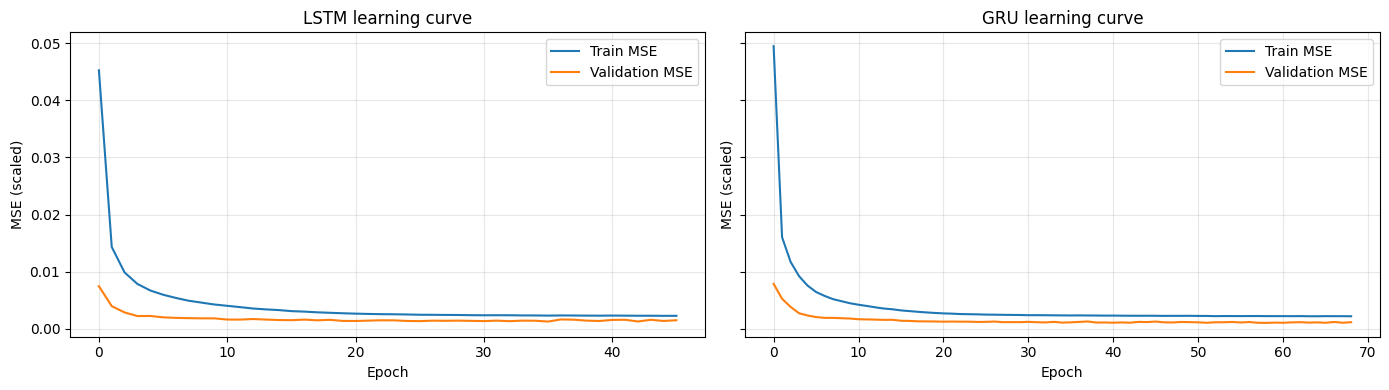

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, name in zip(axes, ['LSTM', 'GRU']):
    hist = histories[name].history
    ax.plot(hist['loss'], label='Train MSE')
    ax.plot(hist['val_loss'], label='Validation MSE')
    ax.set_title(f'{name} learning curve')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('MSE (scaled)')
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

---
## Section 3: Evaluation Metrics & Output Export

### 3.1 Test-set metrics (in MW)
All predictions were already inverse-scaled to MW. For each model we compute:
- **MAE** (MW) — mean absolute error
- **RMSE** (MW) — root mean squared error, penalizes large errors
- **MAPE** (%) — mean absolute percentage error
- **R²** — share of demand variance explained
- **Training time** (s) — wall-clock time of the `fit` call

In [17]:
MODEL_ORDER = ['SARIMAX', 'XGBoost', 'LSTM', 'LightGBM', 'GRU']
MODEL_ROLE = {
    'SARIMAX': 'Baseline 0',
    'XGBoost': 'Baseline 1',
    'LSTM': 'Baseline 2',
    'LightGBM': 'Proposed 1',
    'GRU': 'Proposed 2',
}


def compute_metrics(y_true, y_pred):
    return {
        'MAE (MW)': mean_absolute_error(y_true, y_pred),
        'RMSE (MW)': np.sqrt(mean_squared_error(y_true, y_pred)),
        'MAPE (%)': np.mean(np.abs((y_true - y_pred) / y_true)) * 100,
        'R2': r2_score(y_true, y_pred),
    }


rows = []
for name in MODEL_ORDER:
    rows.append({
        'Model': name,
        'Role': MODEL_ROLE[name],
        **compute_metrics(y_test_mw, predictions[name]),
        'Training Time (s)': train_times[name],
    })

comparison_df = pd.DataFrame(rows).set_index('Model').round(4)
comparison_df

,Role,MAE (MW),RMSE (MW),MAPE (%),R2,Training Time (s)
Model,,,,,,
SARIMAX,Baseline 0,243.2123,321.4613,6.6813,0.6662,11.4757
XGBoost,Baseline 1,104.4544,135.8747,2.7418,0.9404,227.6072
LSTM,Baseline 2,80.3964,106.1198,2.1059,0.9636,68.8733
LightGBM,Proposed 1,95.1069,122.0063,2.5057,0.9519,10.6446
GRU,Proposed 2,82.1851,107.7796,2.1548,0.9625,96.8329


### 3.2 Comparison table (Markdown)
The same table rendered as Markdown, ready to paste into the report. Models are ranked by RMSE, and the table is also saved as `data/comparacion_modelos.csv`.

In [18]:
ranked_df = comparison_df.sort_values('RMSE (MW)')

try:
    print(ranked_df.to_markdown())
except ImportError:
    print(ranked_df.to_string())

ranked_df.to_csv(os.path.join(DATA_DIR, 'comparacion_modelos.csv'))
print(f"\nBest model by RMSE: {ranked_df.index[0]}")

| Model    | Role       |   MAE (MW) |   RMSE (MW) |   MAPE (%) |     R2 |   Training Time (s) |
|:---------|:-----------|-----------:|------------:|-----------:|-------:|--------------------:|
| LSTM     | Baseline 2 |    80.3964 |     106.12  |     2.1059 | 0.9636 |             68.8733 |
| GRU      | Proposed 2 |    82.1851 |     107.78  |     2.1548 | 0.9625 |             96.8329 |
| LightGBM | Proposed 1 |    95.1069 |     122.006 |     2.5057 | 0.9519 |             10.6446 |
| XGBoost  | Baseline 1 |   104.454  |     135.875 |     2.7418 | 0.9404 |            227.607  |
| SARIMAX  | Baseline 0 |   243.212  |     321.461 |     6.6813 | 0.6662 |             11.4757 |

Best model by RMSE: LSTM


### 3.3 Visual check: last 7 days of the test set
Real demand vs. the day-ahead forecast of each model over the final week of the test period.

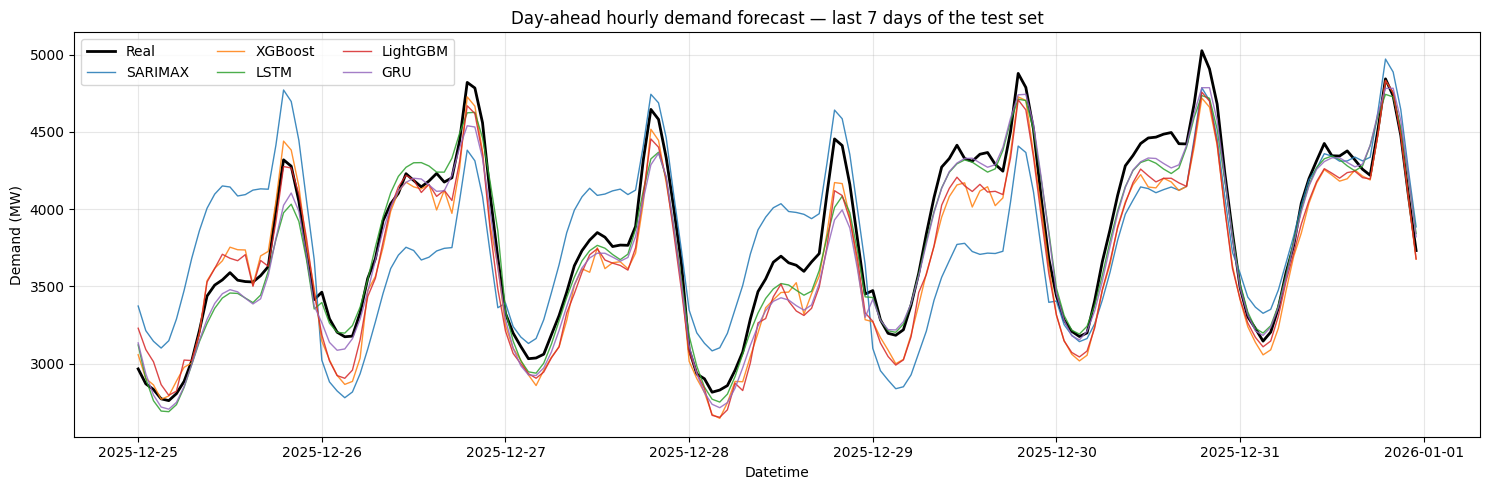

In [19]:
last_hours = 24 * 7

plt.figure(figsize=(15, 5))
plt.plot(test_index[-last_hours:], y_test_mw[-last_hours:], color='black', linewidth=2, label='Real')
for name in MODEL_ORDER:
    plt.plot(test_index[-last_hours:], predictions[name][-last_hours:], linewidth=1, alpha=0.85, label=name)
plt.title('Day-ahead hourly demand forecast — last 7 days of the test set')
plt.xlabel('Datetime')
plt.ylabel('Demand (MW)')
plt.legend(ncol=3)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 3.4 Export test predictions
Ground truth and the five day-ahead forecasts (all in MW) are saved to `data/predicciones_test.csv` for later analysis and plotting.

In [20]:
pred_df = pd.DataFrame({
    'datetime': test_index,
    'real_mw': y_test_mw,
    'pred_sarimax': predictions['SARIMAX'],
    'pred_xgboost': predictions['XGBoost'],
    'pred_lstm': predictions['LSTM'],
    'pred_lightgbm': predictions['LightGBM'],
    'pred_gru': predictions['GRU'],
})

pred_path = os.path.join(DATA_DIR, 'predicciones_test.csv')
pred_df.to_csv(pred_path, index=False)

print(f'Saved {len(pred_df)} rows to {pred_path}')
pred_df.head()

Saved 8895 rows to /content/drive/MyDrive/Project_IA/data/predicciones_test.csv


,datetime,real_mw,pred_sarimax,pred_xgboost,pred_lstm,pred_lightgbm,pred_gru
0,2024-12-26 09:00:00,3578.71,2863.551634,3505.097659,3474.399856,3521.820531,3401.937201
1,2024-12-26 10:00:00,3639.32,2947.044536,3676.952400,3571.482506,3627.165775,3491.354794
2,2024-12-26 11:00:00,3674.53,3031.026815,3617.173732,3628.850425,3634.160022,3543.752121
3,2024-12-26 12:00:00,3635.83,3033.152938,3575.514833,3654.487642,3620.513984,3572.457049
4,2024-12-26 13:00:00,3631.42,3008.700476,3515.390751,3646.522818,3619.505148,3577.456866


### 3.5 Save trained models
Each model is stored in its native format inside `models/`:
- XGBoost → `xgboost_stlf/h01.json … h24.json` (one file per lead time)
- LightGBM → `lightgbm_stlf/h01.txt … h24.txt` (one file per lead time)
- LSTM / GRU → `lstm_stlf.keras`, `gru_stlf.keras`

The fitted scalers and the feature configuration are also saved with `joblib`, since they are required to scale new inputs and inverse-transform forecasts at inference time.

In [21]:
import joblib

xgb_dir = os.path.join(MODELS_DIR, 'xgboost_stlf')
lgb_dir = os.path.join(MODELS_DIR, 'lightgbm_stlf')
os.makedirs(xgb_dir, exist_ok=True)
os.makedirs(lgb_dir, exist_ok=True)

for h, model in xgb_models.items():
    model.save_model(os.path.join(xgb_dir, f'h{h:02d}.json'))
for h, model in lgb_models.items():
    model.booster_.save_model(os.path.join(lgb_dir, f'h{h:02d}.txt'))

saved_paths = {
    'XGBoost': xgb_dir,
    'LightGBM': lgb_dir,
    'LSTM': os.path.join(MODELS_DIR, 'lstm_stlf.keras'),
    'GRU': os.path.join(MODELS_DIR, 'gru_stlf.keras'),
    'Scalers': os.path.join(MODELS_DIR, 'scalers_stlf.joblib'),
}

lstm_model.save(saved_paths['LSTM'])
gru_model.save(saved_paths['GRU'])
joblib.dump({'target_scaler': target_scaler, 'weather_scaler': weather_scaler,
             'horizon': HORIZON, 'n_lags': N_LAGS,
             'seq_features': SEQ_FEATURES, 'seq_len': SEQ_LEN},
            saved_paths['Scalers'])

for name, path in saved_paths.items():
    print(f'{name:<9}-> {path}')

XGBoost  -> /content/drive/MyDrive/Project_IA/models/xgboost_stlf
LightGBM -> /content/drive/MyDrive/Project_IA/models/lightgbm_stlf
LSTM     -> /content/drive/MyDrive/Project_IA/models/lstm_stlf.keras
GRU      -> /content/drive/MyDrive/Project_IA/models/gru_stlf.keras
Scalers  -> /content/drive/MyDrive/Project_IA/models/scalers_stlf.joblib


---
## Summary

- Five STLF models (SARIMAX + four ML/DL models) were trained under identical conditions: same chronological split, same scaling (fitted on training data only), same validation set, and seed `42`.
- All forecasts are **day-ahead**: every day at 23:00, the 24 hours of the next day are forecast with the demand known up to that moment (lead times 1–24 h).
- The comparison table in **3.2** reports MAE, RMSE, MAPE, R² and training time for each model, ranked by RMSE.
- Outputs:
  - `data/predicciones_test.csv`: hourly ground truth plus the five forecasts
  - `data/comparacion_modelos.csv`: metrics table
  - `models/`: serialized models and scalers for deployment